# Quickstart 1: the sinogram fit

**A star has one companion, 200 mas away. The instrument never sees the two on the sky: it gives 47 short
one-dimensional windows, each taken along another scan direction. This notebook goes from those windows to
the companion's position, and then to its proper motion, with a linear fit.**

Each block makes one call, says where the paper defines it, and prints what came back.

| block | task | call | paper |
|---|---|---|---|
| 1 | the instrument | `ins.Instrument.gaussian` | Sect. 2.1, Eqs. 1–4 |
| 2 | the scan law | `scanlaw.load_scan_law` | Sect. 3.1 |
| 3 | the scene, the noise and the windows | `sim.Scene.pair`, `noise.gaia_like`, `sim.simulate_campaign` | Eqs. 3, 9, 21 |
| 4 | one window to positions | `red.ladder_window`, `red.sigma_eta`, `red.delivery_mask` | Sect. 2.2, Fig. 1, App. A |
| 5 | all windows to detections | `red.reduce_campaign` | Eq. 8 |
| 6 | the sinogram | — | Eq. 9, Fig. 2b |
| 7 | the design matrix | `dyn.motion_design` | Eq. 11 |
| 8 | the fit | `dyn.wls`, `dyn.fit_detection_lsq` | Eq. 11 |
| 9 | separation and position angle | `joint.polar_elements` | Eq. 12 |
| 10 | is the fit good? | `ins.project_al` | Sect. 4.4 |
| 11 | a moving companion | `dyn.fit_motion`, `dyn.to_reference_epoch` | Sect. 4.1–4.2, Eqs. 14–17 |
| 12 | a detection that does not belong | `dyn.fit_motion_robust` | — |

**The series.** 1 (this notebook): the sinogram fit. [2](2_binary_backprojected_seed.ipynb): a binary, from the
detections to the joint fit. [3](3_triple_ladder.ipynb): three sources, the search.

**Conventions** ([`docs/conventions.md`](../../docs/conventions.md)): the scan angle ψ in radians,
counter-clockwise from north; sky offsets (Δα\*, Δδ) in mas from the primary; the along-scan coordinate
η = Δα\* sin ψ + Δδ cos ψ in mas; epochs τ in years from the reference epoch; proper motions in mas/yr.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import noise                  # the noise model of a window
from scanlib import scanlaw                # scan angles, epochs and parallax factors
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import reduction as red       # one window, or a campaign, reduced to detections
from scanlib import dynamics as dyn        # the fits to the detections (the sinogram fits)
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the plot style of the paper's figures: small fonts, inward ticks, grays first and one accent colour
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 8.0})
ACCENT = "tomato"

## 1. The instrument

*Paper: Sect. 2.1, Eqs. 1–4.* A window is 18 samples of 59 mas along the scan. A point source puts a Gaussian
line-spread function (LSF) of FWHM 100 mas on them. `margins` are the two thresholds of the per-window source
count (block 4).

In [3]:
# the instrument: the sampling, the LSF, and the thresholds of the per-window source count
inst = ins.Instrument.gaussian(fwhm_mas=100.0, pitch_mas=59.0, n_samples=18, margins=ins.TOY_MARGINS)

grid = inst.sample_grid_mas                      # the centre of each sample in the window's own frame [mas]
print(f"{grid.size} samples from {grid[0]:+.1f} to {grid[-1]:+.1f} mas; LSF FWHM {inst.resolution_mas:.0f} mas")
# inst.margins holds two thresholds: [0] is Delta_1 (one source against two), [1] is Delta_2 (two against three)
print(f"margins: Delta_1 = {inst.margins[0]:.2f} (one source -> two), "
      f"Delta_2 = {inst.margins[1]:.2f} (two -> three)")

18 samples from -501.5 to +501.5 mas; LSF FWHM 100 mas
margins: Delta_1 = 11.12 (one source -> two), Delta_2 = 10.77 (two -> three)


## 2. The scan law

*Paper: Sect. 3.1.* The scan law gives, for each transit, the scan angle ψ and the epoch τ. The package
carries one law, for the centre of the Pleiades over the span of Gaia DR4.

In [4]:
# the scan law: the scan angle [rad] and the epoch [yr from the reference epoch] of each transit
psi, tau = scanlaw.load_scan_law(scanlaw.PLEIADES)

print(f"{psi.size} transits over {tau.max() - tau.min():.1f} yr, tau from {tau.min():+.2f} to {tau.max():+.2f} yr")
psi_folded_deg = np.rad2deg(psi) % 180           # the scan angles [deg], folded to the half-turn [0, 180)
print(f"scan angles cover {np.ptp(psi_folded_deg):.0f} deg of the half-turn")          # np.ptp: largest - smallest

47 transits over 5.1 yr, tau from -2.36 to +2.72 yr
scan angles cover 171 deg of the half-turn


## 3. The scene and its windows

*Paper: Eq. 9 (where a source falls along the scan), Eq. 3 (the window it makes).* The scene is the truth. It
is used here to make the windows, and again only where a cell says "truth".

`sim.Scene.pair` puts the primary at the origin and a companion at a separation and a position angle.
`sim.simulate_campaign` renders one noisy window per transit.

**The units and the noise** (*Paper: Sect. 5.2, Eq. 21*). The windows are in the package's flux units: the
primary's total flux is `sim.PRIMARY_FLUX` = 1000, whatever its magnitude, and the companion has 0.2 of that.
The noise is a matter of electrons. `noise.gaia_like(G, flux)` takes the magnitude of the primary and its flux
in the windows' units, and does three steps for each sample:

1. to electrons: a G = 16 primary gives 3.0 × 10⁵ electrons per transit (`noise.gaia_electrons`), so one flux
   unit is 301 electrons;
2. the noise in electrons: σ_e² = (the sample's electrons) + 9 (b + r²), the shot noise of the signal, and the
   background b = 10 e⁻ and the read noise r = 4.3 e⁻ of the nine CCD crossings of a transit;
3. back to flux units: σ = σ_e / 301.

A sample's signal over its σ is the same in electrons and in flux units. The magnitude sets it: a fainter
primary has the same windows and more noise. With data in electrons, `flux` is the source's electrons and one
unit is one electron.

In [5]:
# the truth: a companion at rest, 200 mas from the primary at position angle 110 deg, 0.2 of its flux
RHO = 200.0                                      # the separation [mas]
PA = 110.0                                       # the position angle [deg], from north through east
Q = 0.2                                          # the flux ratio, companion over primary
scene = sim.Scene.pair(RHO, PA, Q)

print("positions [mas]:", scene.positions.round(1).tolist())
print("fluxes:", scene.fluxes.tolist())

positions [mas]: [[0.0, 0.0], [187.9, -68.4]]
fluxes: [1000.0, 200.0]


In [6]:
# the noise of a G = 16 primary whose total flux is sim.PRIMARY_FLUX in the windows' units; noise_model.sigma
# gives the sigma of a sample from its noise-free value, both in flux units
noise_model = noise.gaia_like(16.0, sim.PRIMARY_FLUX)

electrons_per_transit = noise.gaia_electrons(16.0)
print(f"a G = 16 primary: {electrons_per_transit:.3g} electrons per transit, "
      f"so one flux unit is {noise_model.gain:.0f} electrons")
# two samples as examples: a label, and the sample's noise-free value [flux units]
for name, value in (("the primary's peak sample", 550.0), ("an empty sample", 0.0)):
    sigma_sample = float(noise_model.sigma(value))                 # the sigma of that sample [flux units]
    print(f"  {name}: {value:5.0f} flux units = {value * noise_model.gain:8.0f} e-;  "
          f"sigma = {sigma_sample * noise_model.gain:5.1f} e- = {sigma_sample:.3f} flux units")

a G = 16 primary: 3.01e+05 electrons per transit, so one flux unit is 301 electrons
  the primary's peak sample:   550 flux units =   165494 e-;  sigma = 407.1 e- = 1.353 flux units
  an empty sample:     0 flux units =        0 e-;  sigma =  16.0 e- = 0.053 flux units


In [7]:
# each window's zero point: where its sample 0 sits on the sky [mas], a random sampling phase per window
SEED = 7                                         # the seed of the noise draw
# rng_zero_points: the generator of the zero points, their own stream, so the noise does not depend on them. Its
# seed is a list of two whole numbers: [the noise seed, the label 1 of this stream]
rng_zero_points = np.random.default_rng([SEED, 1])
eta0 = sim.random_zero_points(rng_zero_points, psi.size, inst)     # where sample 0 sits on the sky [mas]

print(f"zero points eta0 from {eta0.min():+.1f} to {eta0.max():+.1f} mas (a random sampling phase per window)")

zero points eta0 from -28.1 to +29.1 mas (a random sampling phase per window)


In [8]:
# the windows: one per transit, with the noise sigma of every sample
# rng_noise: the generator of the windows' noise; its seed is SEED alone. sim.simulate_campaign also returns the
# sources' true positions along the scan (dropped here, the name _)
rng_noise = np.random.default_rng(SEED)
windows, sigma, _ = sim.simulate_campaign(scene, (psi, tau), rng_noise, inst, noise_model, eta0=eta0)
windows = np.asarray(windows)                    # one array (transits, samples) in place of a list of windows
sigma = np.asarray(sigma)

print(f"windows {windows.shape} [flux per sample]; sigma {sigma.shape}, from {sigma.min():.1f} to {sigma.max():.1f}")

windows (47, 18) [flux per sample]; sigma (47, 18), from 0.1 to 1.5


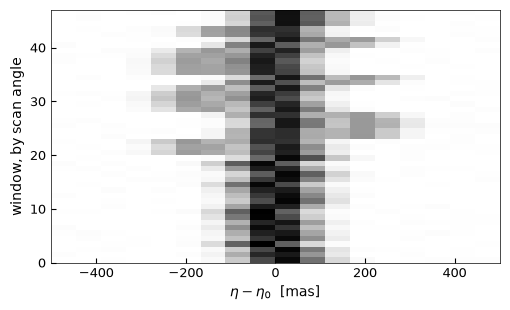

In [9]:
# what the instrument gives: the 47 windows, ordered by scan angle; the primary is the dark band at 0, the
# companion the fainter one beside it
order = np.argsort(psi % np.pi)                  # the windows' order by scan angle, folded to the half-turn [0, pi)
# the image: the windows in that order, on a square-root scale; np.clip(..., 0, None) sets negative samples to 0
image = np.sqrt(np.clip(windows[order], 0, None))
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.imshow(image, aspect="auto", cmap="gray_r", origin="lower",
          extent=(grid[0], grid[-1], 0, psi.size), interpolation="nearest")
ax.set(xlabel=r"$\eta - \eta_0$  [mas]", ylabel="window, by scan angle")
plt.tight_layout()
plt.show()

## 4. One window: positions along the scan

*Paper: Sect. 2.2, Fig. 1, App. A.* `red.ladder_window` fits one source, then two, and keeps the larger model
only when χ² improves by more than the margin Δ₁. It returns the positions η in the window's frame, the
fluxes, the number of sources K, and the χ² of each step.

In [10]:
# reduce one window: how many sources, and where along the scan
j = 9                                            # the window to reduce: transit number 9, counted from 0
eta_j, flux_j, k_j, diag_j = red.ladder_window(windows[j], inst, sigma[j], k_max=2)

# diag_j["chi2"]: the misfit of every fit made, [0] with one source and [1] with two; diag_j["delta_chi2"][0]:
# the improvement from one source to two, which is tested against Delta_1

print(f"window {j}: K = {k_j};  chi2 with one source {diag_j['chi2'][0]:.0f}, with two {diag_j['chi2'][1]:.0f}; "
      f"improvement {diag_j['delta_chi2'][0]:.0f} against Delta_1 = {inst.margins[0]:.2f}")
print("positions [mas, window frame]:", eta_j.round(2).tolist(), " fluxes:", flux_j.round(1).tolist())

window 9: K = 2;  chi2 with one source 2137, with two 13; improvement 2124 against Delta_1 = 11.12
positions [mas, window frame]: [-1.53, 37.58]  fluxes: [993.4, 205.9]


`red.sigma_eta` gives the error of each position, from the window's Fisher matrix. `red.delivery_mask` says which
source is a **detection**: every source except the one nearest the primary's expected place, which is
`-eta0[j]` in the window's frame.

In [11]:
# the error of each position, and which one is the detection (not the primary)
err_j = red.sigma_eta(eta_j, flux_j, inst, sigma[j])
is_detection = red.delivery_mask(eta_j, origin=-eta0[j])

for eta_source, err_source, delivered in zip(eta_j, err_j, is_detection):
    if delivered:
        label = "a detection"
    else:
        label = "the primary"
    # + eta0[j] moves the position from the window's frame to the sky
    print(f"  eta {eta_source + eta0[j]:+8.2f} +- {err_source:.2f} mas on the sky: {label}")
# truth: scene.along_scan gives every source's position along this scan; [1] is the companion ([0] the primary)
print(f"truth (Eq. 9): the companion is at {scene.along_scan(psi[j])[1]:+.2f} mas in this scan")

  eta    -0.08 +- 0.36 mas on the sky: the primary
  eta   +39.03 +- 1.46 mas on the sky: a detection
truth (Eq. 9): the companion is at +39.78 mas in this scan


**Options of `red.ladder_window`.** `k_max`: the largest number of sources tried (2 here; 3 in notebook 3).
`sigma_noise` (third argument): one number, or one value per sample as here.

## 5. All windows: the detections

*Paper: Eq. 8.* `red.reduce_campaign` does block 4 for every window. It returns a `DetectionSet`: for each
detection its scan angle `psi`, its epoch `tau`, its position `eta` on the sky and the error `sigma`. This
table of (ψ, τ, η, σ) is all that the sinogram fit uses.

In [12]:
# reduce every window: the detection set (psi, tau, eta, sigma)
det = red.reduce_campaign((psi, tau), windows, inst, sigma, k_max=2, eta0=eta0)

print(f"{det.eta.size} detections from {det.n_windows_with_detection} of {det.n_windows} windows; "
      f"{det.n_censored_windows} windows gave none")
print(f"errors sigma from {det.sigma.min():.2f} to {det.sigma.max():.2f} mas, median {np.median(det.sigma):.2f}")

42 detections from 42 of 47 windows; 5 windows gave none
errors sigma from 0.19 to 17.74 mas, median 0.21


A window gives no detection when the companion falls on the primary along that scan: the two blend, and the
ladder keeps one source. These windows are **censored**. The joint fit of notebook 2 uses them again.

## 6. The sinogram

*Paper: Eq. 9, Fig. 2b.* A source at (Δα\*, Δδ) is seen in a scan of angle ψ at

$$\eta(\psi) = \Delta\alpha^{*}\sin\psi + \Delta\delta\cos\psi .$$

So the detections of one source lie on a sinusoid in the (ψ, η) plane. This plot is the sinogram.

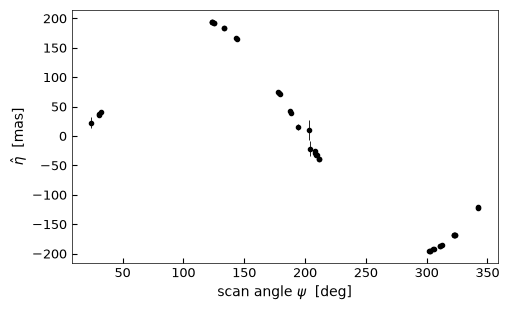

In [13]:
# the sinogram: each detection's position along the scan against its scan angle
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.errorbar(np.rad2deg(det.psi) % 360, det.eta, yerr=det.sigma, fmt="o", color="k", ms=3, elinewidth=0.6)
ax.set(xlabel=r"scan angle $\psi$  [deg]", ylabel=r"$\hat\eta$  [mas]")
plt.tight_layout()
plt.show()

## 7. The design matrix

*Paper: Eq. 11.* Eq. 9 is linear in (Δα\*, Δδ). With one row per detection, η = **X** a, where the row of
detection *i* is (sin ψᵢ, cos ψᵢ). `dyn.motion_design` builds **X**; its first two columns are these, and the
next two belong to the motion (block 11).

In [14]:
# the design matrix of a source at rest: one row (sin psi, cos psi) per detection.
# dyn.motion_design returns four columns (sin psi, cos psi, tau sin psi, tau cos psi); [:, :2] keeps every row
# and the first two columns, so we omit the two proper-motion columns (block 11 uses them)
X = dyn.motion_design(det.psi, det.tau)[:, :2]

print("X has shape", X.shape, "; its first three rows:")
print(X[:3].round(3))
assert np.array_equal(X, np.column_stack([np.sin(det.psi), np.cos(det.psi)]))

X has shape (42, 2) ; its first three rows:
[[-0.498 -0.867]
 [ 0.032 -0.999]
 [ 0.027 -1.   ]]


## 8. The fit

*Paper: Eq. 11.* The weighted least-squares solution, with weights 1/σ²:

$$\hat{\mathbf a} = (\mathbf X^{\intercal}\mathbf W\mathbf X)^{-1}\mathbf X^{\intercal}\mathbf W\,\hat{\boldsymbol\eta},
\qquad \mathrm{cov}(\hat{\mathbf a}) = (\mathbf X^{\intercal}\mathbf W\mathbf X)^{-1}.$$

`dyn.wls` returns both.

In [15]:
# the fit of Eq. 11: the companion's offset and its covariance
weight = 1.0 / det.sigma ** 2                    # the weight of each detection, 1 / sigma^2 [1/mas^2]
a_hat, a_cov = dyn.wls(X, det.eta, weight)
a_err = np.sqrt(np.diag(a_cov))                  # the errors: the square roots of the covariance's diagonal

print(f"dra*  = {a_hat[0]:+8.2f} +- {a_err[0]:.2f} mas")
print(f"ddec  = {a_hat[1]:+8.2f} +- {a_err[1]:.2f} mas")

dra*  =  +188.02 +- 0.13 mas
ddec  =   -68.32 +- 0.14 mas


In [16]:
# the same fit in one call
a_one, cov_one = dyn.fit_detection_lsq(det.psi, det.eta, det.sigma)

assert np.allclose(a_one, a_hat) and np.allclose(cov_one, a_cov)
print("dyn.fit_detection_lsq gives the same offset and covariance")

dyn.fit_detection_lsq gives the same offset and covariance


## 9. Separation and position angle

*Paper: Eq. 12.* `joint.polar_elements` changes (Δα\*, Δδ) and its covariance into the separation ρ and the
position angle (from north through east), with their errors.

In [17]:
# the offset as a separation and a position angle, with errors
rho, rho_err, pa, pa_err = joint.polar_elements(a_hat, a_cov)

print(f"rho = {rho:.2f} +- {rho_err:.2f} mas   (truth {RHO:.0f})")
print(f"PA  = {pa:.2f} +- {pa_err:.2f} deg   (truth {PA:.0f})")

rho = 200.05 +- 0.08 mas   (truth 200)
PA  = 109.97 +- 0.05 deg   (truth 110)


## 10. Is the fit good?

*Paper: Sect. 4.4.* Two checks, without the truth: the fitted curve must pass through the points, and the
residuals divided by their errors (the pulls) must scatter by about 1. `ins.project_al` is Eq. 9: the along-scan
position of a sky offset.

In [18]:
# the residuals from the fitted curve, in units of their errors
pull = (det.eta - ins.project_al(a_hat[0], a_hat[1], det.psi)) / det.sigma

print(f"chi2 = {np.sum(pull ** 2):.1f} for {det.eta.size} detections and 2 parameters")
print(f"pulls: rms {np.sqrt(np.mean(pull ** 2)):.2f}, largest {np.abs(pull).max():.1f}")

chi2 = 38.1 for 42 detections and 2 parameters
pulls: rms 0.95, largest 2.3


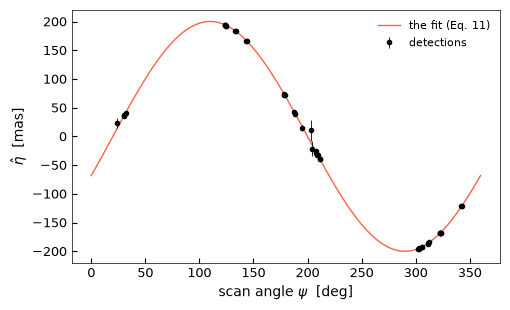

In [19]:
# the sinogram with the fitted curve
fine = np.linspace(0, 2 * np.pi, 400)            # 400 scan angles over the full turn [rad], to draw the curve
curve_fine = ins.project_al(a_hat[0], a_hat[1], fine)              # the fitted sinusoid at those angles [mas]
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(np.rad2deg(fine), curve_fine, "-", color=ACCENT, lw=1.0, label="the fit (Eq. 11)")
ax.errorbar(np.rad2deg(det.psi) % 360, det.eta, yerr=det.sigma, fmt="o", color="k", ms=3, elinewidth=0.6,
            label="detections")
ax.set(xlabel=r"scan angle $\psi$  [deg]", ylabel=r"$\hat\eta$  [mas]")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

Here the fit is good: the pair is wide, and the pulls scatter by about 1. The fit has two limits. A detection
close to the primary is pulled toward it by the blend (Eq. 2), and the censored windows are not used. They
matter for a closer or fainter companion. For this reason the paper uses the sinogram fit as a **starting
point**, and takes the measurement from the joint fit of all windows (notebook 2).

## 11. A moving companion

*Paper: Sect. 4.1, Eq. 14 (the motion); Sect. 4.2, Eqs. 15–16 (the fit); Eq. 17 (the correction).* A companion
with proper motion (μα\*, μδ) is at (Δα\* + μα\* τ, Δδ + μδ τ) at epoch τ. Its along-scan position stays
linear in the four parameters:

$$\eta_i = (\Delta\alpha^{*} + \mu_{\alpha^*}\tau_i)\sin\psi_i + (\Delta\delta + \mu_\delta\tau_i)\cos\psi_i .$$

The same blocks, with two more columns.

In [20]:
# the truth: the same companion, now moving (3, 9) mas/yr relative to the primary; windows and detections as before
PM = (3.0, 9.0)                                  # the proper motion (mu_a*, mu_d) [mas/yr]
scene_m = sim.Scene.pair(RHO, PA, Q, pm=PM)
rng_noise_m = np.random.default_rng(SEED)        # the same seed as in block 3: the same noise draw
windows_m, sigma_m, _ = sim.simulate_campaign(scene_m, (psi, tau), rng_noise_m, inst, noise_model, eta0=eta0)
det_m = red.reduce_campaign((psi, tau), windows_m, inst, sigma_m, k_max=2, eta0=eta0)

# np.hypot(*PM): the size of the proper motion [mas/yr]; *PM passes its two components
path_mas = np.hypot(*PM) * (tau.max() - tau.min())
print(f"{det_m.eta.size} detections; the companion moves {path_mas:.0f} mas over the campaign")

44 detections; the companion moves 48 mas over the campaign


In [21]:
# the design matrix with motion: the columns (sin psi, cos psi, tau sin psi, tau cos psi)
X_m = dyn.motion_design(det_m.psi, det_m.tau)

print("X has shape", X_m.shape, "; its first row:", X_m[0].round(3).tolist())

X has shape (44, 4) ; its first row: [-0.498, -0.867, 1.172, 2.044]


In [22]:
# the fit: position at the reference epoch and proper motion, by the same dyn.wls
weight_m = 1.0 / det_m.sigma ** 2                # the weight of each detection, 1 / sigma^2 [1/mas^2]
theta_m, cov_m = dyn.wls(X_m, det_m.eta, weight_m)
err_m = np.sqrt(np.diag(cov_m))

names = ("dra*  [mas]", "ddec  [mas]", "mu_a* [mas/yr]", "mu_d  [mas/yr]")
# truth: the companion's position (row 1 of the scene's positions; row 0 is the primary), then its motion
truth = (*scene_m.positions[1], *PM)
for name, value, error, true_value in zip(names, theta_m, err_m, truth):
    print(f"  {name:15s} {value:+8.2f} +- {error:.2f}   (truth {true_value:+.2f})")

  dra*  [mas]      +187.99 +- 0.13   (truth +187.94)
  ddec  [mas]       -68.37 +- 0.14   (truth -68.40)
  mu_a* [mas/yr]     +2.92 +- 0.08   (truth +3.00)
  mu_d  [mas/yr]     +8.96 +- 0.07   (truth +9.00)


In [23]:
# the same fit in one call; it also returns the detections moved to the reference epoch (Eq. 17)
theta_one, cov_one, eta_ref = dyn.fit_motion(det_m.psi, det_m.tau, det_m.eta, det_m.sigma)

assert np.allclose(theta_one, theta_m) and np.allclose(cov_one, cov_m)
assert np.allclose(eta_ref, dyn.to_reference_epoch(theta_m, det_m.psi, det_m.tau, det_m.eta))
largest_shift = np.abs(eta_ref - det_m.eta).max()                  # [mas]
print(f"dyn.fit_motion gives the same; the correction of Eq. 17 moves a detection by up to {largest_shift:.1f} mas")

dyn.fit_motion gives the same; the correction of Eq. 17 moves a detection by up to 25.1 mas


`dyn.to_reference_epoch` is Eq. 17: it subtracts the fitted motion from each detection,
η − μα\* τ sin ψ − μδ τ cos ψ. As measured, the detections leave the sinusoid of the fitted position by up to
25 mas, more at the early and late epochs. After the correction they lie on it.

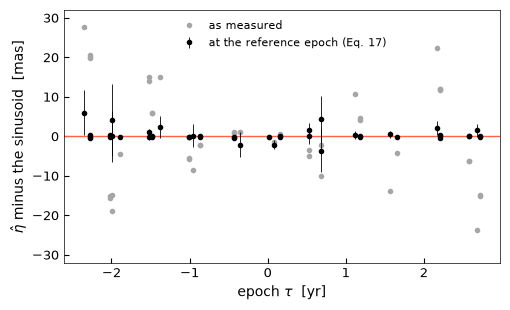

In [24]:
# each detection's distance from the sinusoid of the fitted position: as measured, and after Eq. 17
curve = ins.project_al(theta_m[0], theta_m[1], det_m.psi)          # [0], [1]: the fitted (dra*, ddec) [mas]
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.axhline(0.0, color=ACCENT, lw=1.0)
ax.plot(det_m.tau, det_m.eta - curve, "o", color="0.65", ms=3, label="as measured")
ax.errorbar(det_m.tau, eta_ref - curve, yerr=det_m.sigma, fmt="o", color="k", ms=3, elinewidth=0.6,
            label="at the reference epoch (Eq. 17)")
ax.set(xlabel=r"epoch $\tau$  [yr]", ylabel=r"$\hat\eta$ minus the sinusoid  [mas]", ylim=(-32, 32))
ax.legend(loc="upper center")
plt.tight_layout()
plt.show()

**The parallax option.** A companion at another distance also shows a parallax difference Δϖ. It adds a fifth
column, the along-scan parallax factor of each detection (`scanlaw.load_parallax_factor`, carried by the detection
set as `det.fpar` when the scan law is given as `(psi, tau, fpar)`).

In [25]:
# five parameters: position, proper motion and parallax difference (this companion has none)
fpar = scanlaw.load_parallax_factor(scanlaw.PLEIADES)
det_p = red.reduce_campaign((psi, tau, fpar), windows_m, inst, sigma_m, k_max=2, eta0=eta0)
# the third return of dyn.fit_motion, the detections at the reference epoch, is dropped (the name _)
theta_p, cov_p, _ = dyn.fit_motion(det_p.psi, det_p.tau, det_p.eta, det_p.sigma, fpar=det_p.fpar, parallax=True)

# entry 4 of theta_p, the fifth, is the parallax difference [mas]; cov_p[4, 4] is its variance
print(f"parallax difference = {theta_p[4]:+.2f} +- {np.sqrt(cov_p[4, 4]):.2f} mas   (truth 0)")

parallax difference = -0.11 +- 0.08 mas   (truth 0)


## 12. A detection that does not belong

A real detection set can hold a line of another source. Least squares gives it full weight. The Huber fit
`dyn.fit_motion_robust` gives each detection the weight 1 while its pull is below `delta`, and `delta`/|pull|
above it. The default `delta` is 1.345 (`dyn.HUBER_DELTA`).

In [26]:
# put one wrong detection in the set: detection 5 moved by 60 mas
eta_bad = det_m.eta.copy()
eta_bad[5] += 60.0

# the returns that are dropped (the names _): the detections at the reference epoch, and the covariance of the
# least-squares fit
theta_ls, _, _ = dyn.fit_motion(det_m.psi, det_m.tau, eta_bad, det_m.sigma)
theta_hub, cov_hub, weights, _ = dyn.fit_motion_robust(det_m.psi, det_m.tau, eta_bad, det_m.sigma,
                                                       delta=dyn.HUBER_DELTA)

print("least squares: ", theta_ls.round(2).tolist())
print("Huber:         ", theta_hub.round(2).tolist())
print("without the bad detection (block 11):", theta_m.round(2).tolist())
other_weights = np.delete(weights, 5)            # the Huber weights of all the detections but number 5
print(f"Huber weight of the bad detection: {weights[5]:.3f}; median of the others: {np.median(other_weights):.2f}")

least squares:  [192.73, -61.37, 0.8, 5.62]
Huber:          [188.04, -68.31, 2.9, 8.92]
without the bad detection (block 11): [187.99, -68.37, 2.92, 8.96]
Huber weight of the bad detection: 0.006; median of the others: 1.00


**Options of `dyn.fit_motion_robust`.** `delta`: the pull where the weight starts to fall (default 1.345; smaller
is more robust and less precise). `n_iter`: the largest number of reweighting passes (default 25).
`fpar`, `parallax`: as `dyn.fit_motion`.

## What is next

The sinogram fit needs to know **which detections belong to the source**. [Notebook 2](2_binary_backprojected_seed.ipynb)
finds them with the triangulation map, refines the set with the fit of this notebook, and then makes the
measurement with the joint fit of all windows.